# A tour of the data

This notebook walks through the data behind the project and what we learned from it
before building any model. Every table and figure here comes from the pipeline
(`make all`). The notebook only reads them; it does no analysis of its own.
It was run on the real data and saved with its results, so you can read it without
the data.

## The question

Investors often pick stocks with **multi-criteria decision making (MCDM)**: give each
company a score on a few criteria (for example how much debt it has, or how profitable
it is), weight the scores, and rank the companies.

The project asks one question: **does adding "intelligence" to this ranking help it
avoid the stocks that fall hardest?** We compare three layers of criteria:

1. six textbook financial ratios,
2. a risk score from a machine-learning model,
3. facts that a language model (an **LLM**) reads out of each company's annual report.

A stock "falls hardest" when its return over the next year is among the worst 20% of
all companies that year. We call such a company a **tail loser**. The cut-off is set
again each year, because some years the whole market falls.

## The data

We combine three sources, all about US companies for fiscal years 2014 to 2018:

| Source | What it gives us |
|---|---|
| Kaggle "200+ Financial Indicators of US Stocks" | About 220 numbers per company and year (sales, debt, profit, ratios), its sector, and its price change over the next year |
| The SEC (the US market regulator) | Each company's official identity, its filing dates, and its reported figures in **XBRL**, a machine-readable format |
| EDGAR-CORPUS | The text of each company's **10-K**, the annual report every US listed company must file, split into its sections ("Items") |

The years 2017 and 2018 are kept aside for the final test of the ranking. They appear
below only in simple counts and descriptions of the data; nothing in this notebook uses
a model, and no model result appears here.

In [1]:
import pandas as pd
from IPython.display import Image, display

from ai_mcdm_invest.config import Settings

settings = Settings.from_env()
panel = pd.read_parquet(settings.processed_dir / "panel.parquet")
filings = pd.read_parquet(settings.processed_dir / "filings.parquet")


def show(figure: str) -> None:
    """Display one of the pipeline's saved figures."""
    display(Image(filename=settings.figures_dir / f"{figure}.png", width=900))

## The joined panel

The main table has one row per company and fiscal year. Here are a few columns of the
first rows, which happen to be one company across its five years:

- `ticker` is the short code the stock trades under (like AAPL for Apple),
- `market_cap_billion` is what the whole company was worth on the market, in billions of dollars,
- `debtEquityRatio` is its debt divided by its own capital (one of the six textbook ratios),
- `next_year_return` is its price change in percent over the following year,
- `tail_loss` says whether it was a tail loser that year.

In [2]:
panel.assign(market_cap_billion=panel["Market Cap"] / 1e9)[
    ["ticker", "fiscal_year", "sector", "market_cap_billion", "debtEquityRatio"]
    + ["next_year_return", "tail_loss"]
].head().round(2)

,ticker,fiscal_year,sector,market_cap_billion,debtEquityRatio,next_year_return,tail_loss
0,AIR,2014,Industrials,0.97,0.63,-2.31,False
1,AIR,2015,Industrials,1.18,0.18,29.71,False
2,AIR,2016,Industrials,0.85,0.17,19.17,False
3,AIR,2017,Industrials,1.20,0.17,-4.70,False
4,AIR,2018,Industrials,1.55,0.19,21.38,False


How many companies we have each year, and how many of them are tail losers (about one
in five, by construction):

In [3]:
panel.groupby("fiscal_year").agg(
    companies=("cik", "size"),
    tail_losers=("tail_loss", "sum"),
)

,companies,tail_losers
fiscal_year,,
2014,3393,670
2015,3693,738
2016,4157,852
2017,4269,891
2018,3971,798


## The filings table

A second table describes each company's 10-K for the same year: when it was filed,
which sections it has, and how long they are. Lengths are counted in **tokens**, the
pieces of text a language model reads; one token is about four characters.

Here are a few rows: the filing date, how many days after the end of the fiscal year it
came, whether the risk-factor section (Item 1A) is there, and its length in tokens.

In [4]:
filings[
    ["ticker", "fiscal_year", "filing_date", "days_after_fy_end", "has_item_1A", "tokens_item_1A"]
].head()

,ticker,fiscal_year,filing_date,days_after_fy_end,has_item_1A,tokens_item_1A
0,AIR,2014,2014-07-17,47,True,7103
1,AIR,2015,2015-07-15,45,True,6480
2,AIR,2016,2016-07-13,43,True,6492
3,AIR,2017,2017-07-12,42,True,6632
4,AIR,2018,2018-07-11,41,True,6182


Percentage of companies each year for which we found the 10-K text:

In [5]:
(filings.groupby("fiscal_year")["in_corpus"].mean() * 100).round()

fiscal_year
2014    82.0
2015    81.0
2016    76.0
2017    79.0
2018    85.0
Name: in_corpus, dtype: float64

# The story in four figures

These four figures carry the argument of the report.

## 1. Linking companies by ticker alone loses the companies we care about

The Kaggle data names companies only by their ticker, and the SEC's list of tickers is
today's. Since 2014 many tickers were renamed, dropped or given to a new company.
Linking by ticker alone keeps only about 60% of companies, and fewer than half of the
tail losers, most likely because companies that crash are the ones that later disappear,
merge or change name.

So we also link each company by its numbers: its total assets, plus its sales or profit,
must match one SEC company's XBRL figures almost exactly. This brings both companies and
tail losers back to about 90%.

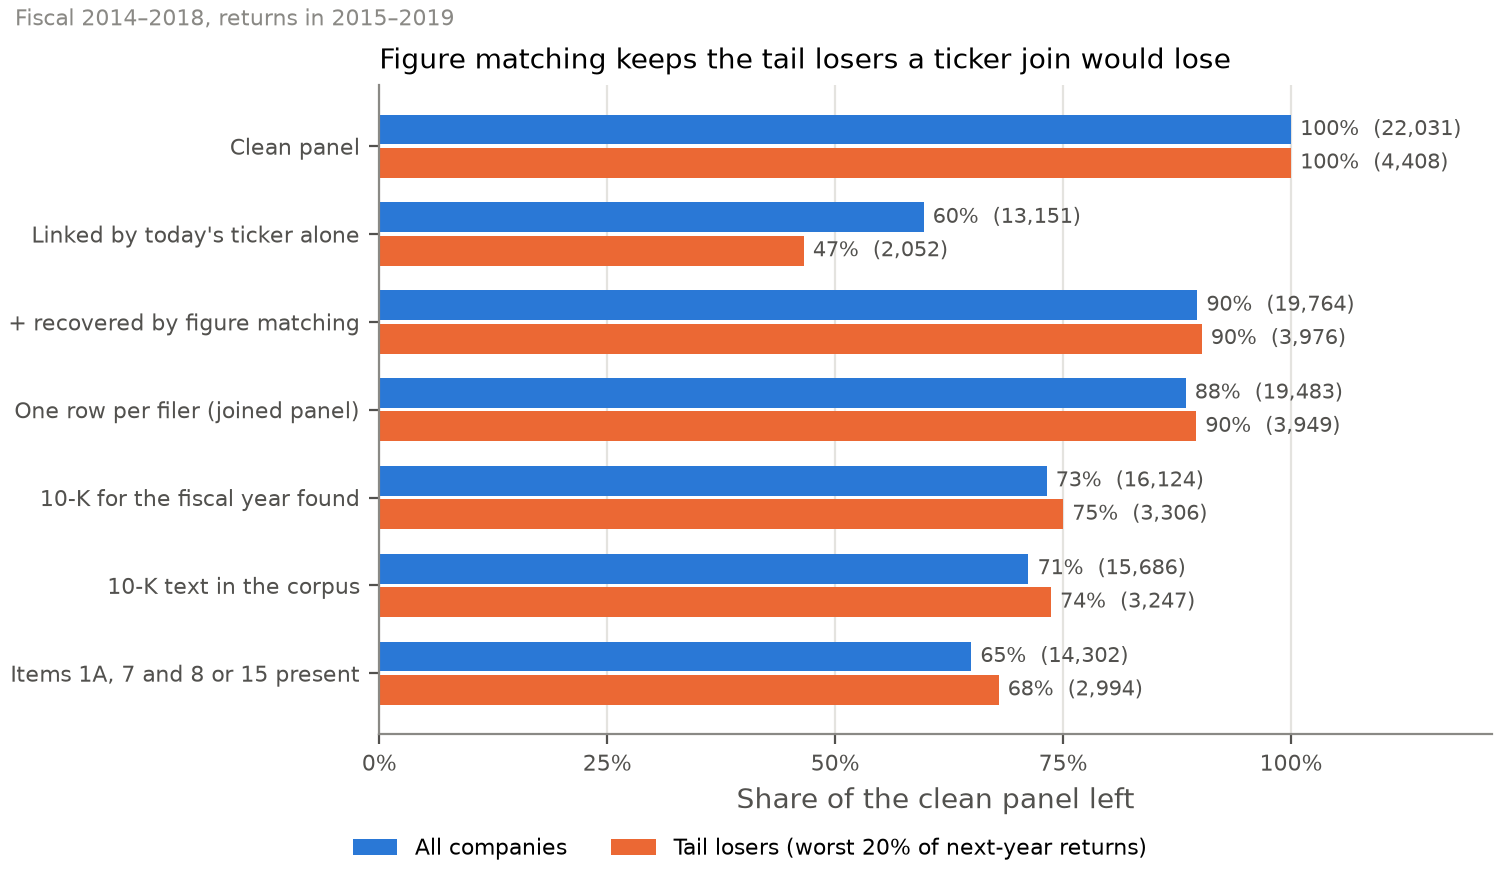

In [6]:
show("join_funnel")

**What this tells us:** how we link the data decides which companies stay in the study,
and the easy way would quietly drop the cases the study is about.

## 2. The textbook reading of debt is wrong across the market

Textbooks say more debt means more risk. Across the whole market we see the opposite:
the companies with the least debt (compared with their equity) are the most likely to be
tail losers. The reason is the sector (right): utilities and real estate carry the most
debt but are among the safest, while healthcare carries the least debt and has the most
tail losers.
When we compare companies only within their own sector (orange), the pattern mostly
flattens.

A **quintile** is one fifth of the companies, sorted by a value.

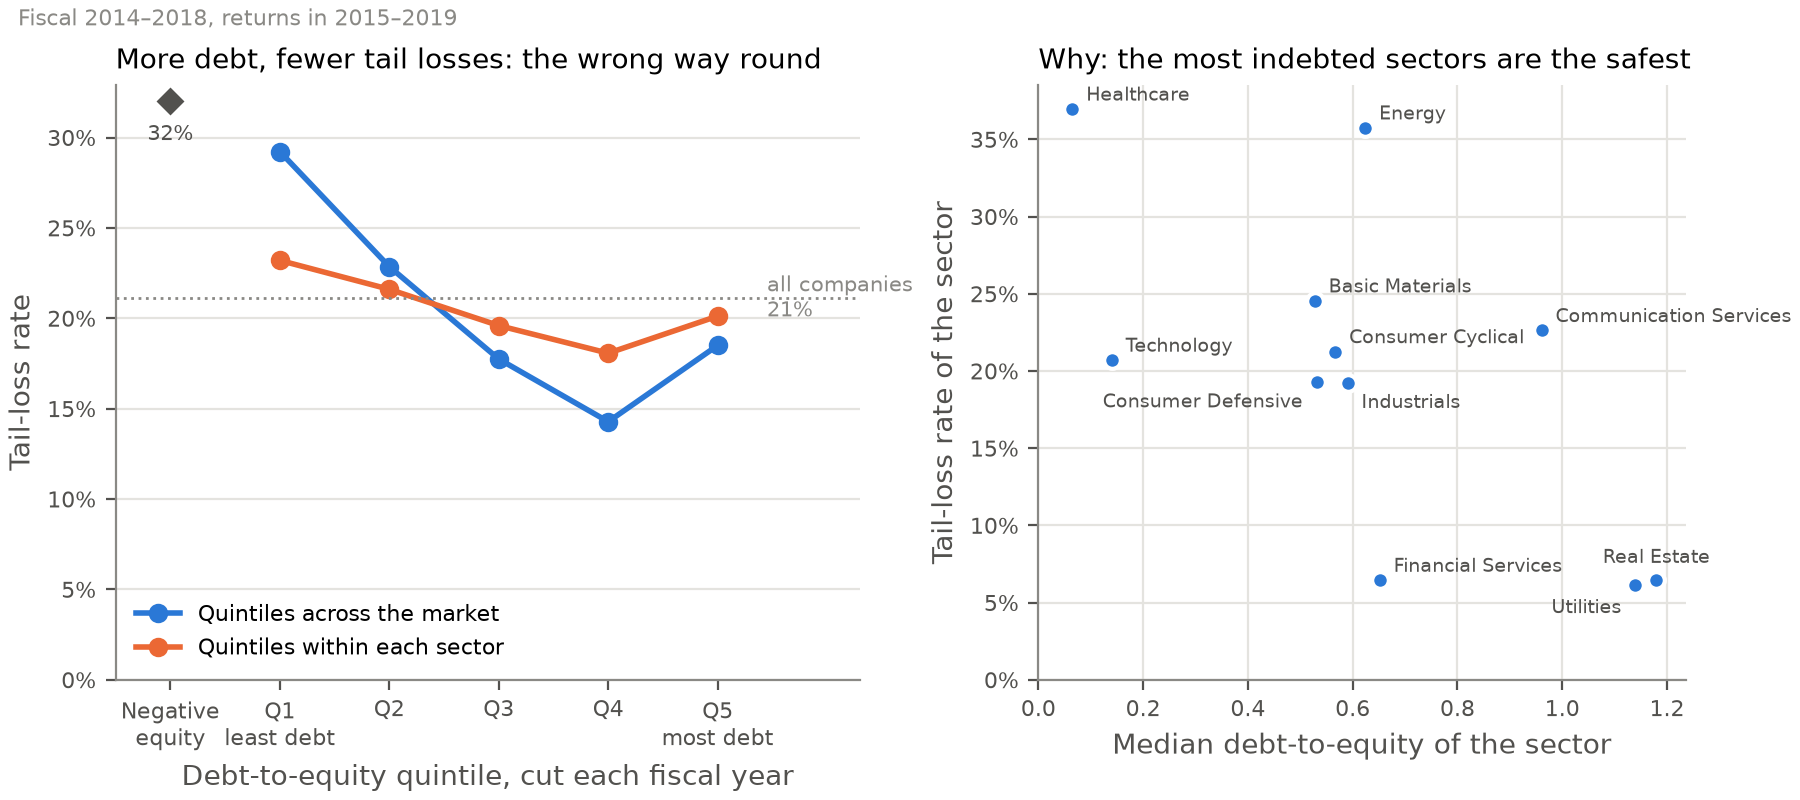

In [7]:
show("leverage_tail_loss")

**What this tells us:** a ratio only means something next to companies of the same
kind, so the ranking has to take the sector into account.

## 3. Many 10-K sections are too long for our language model

We run a language model on our own computer, and it can read 32,768 tokens at once (the
orange line). About 1 in 10 risk-factor sections (Item 1A) and 1 in 5 financial-statement
sections (Item 8) are longer than that, before we even add our question.

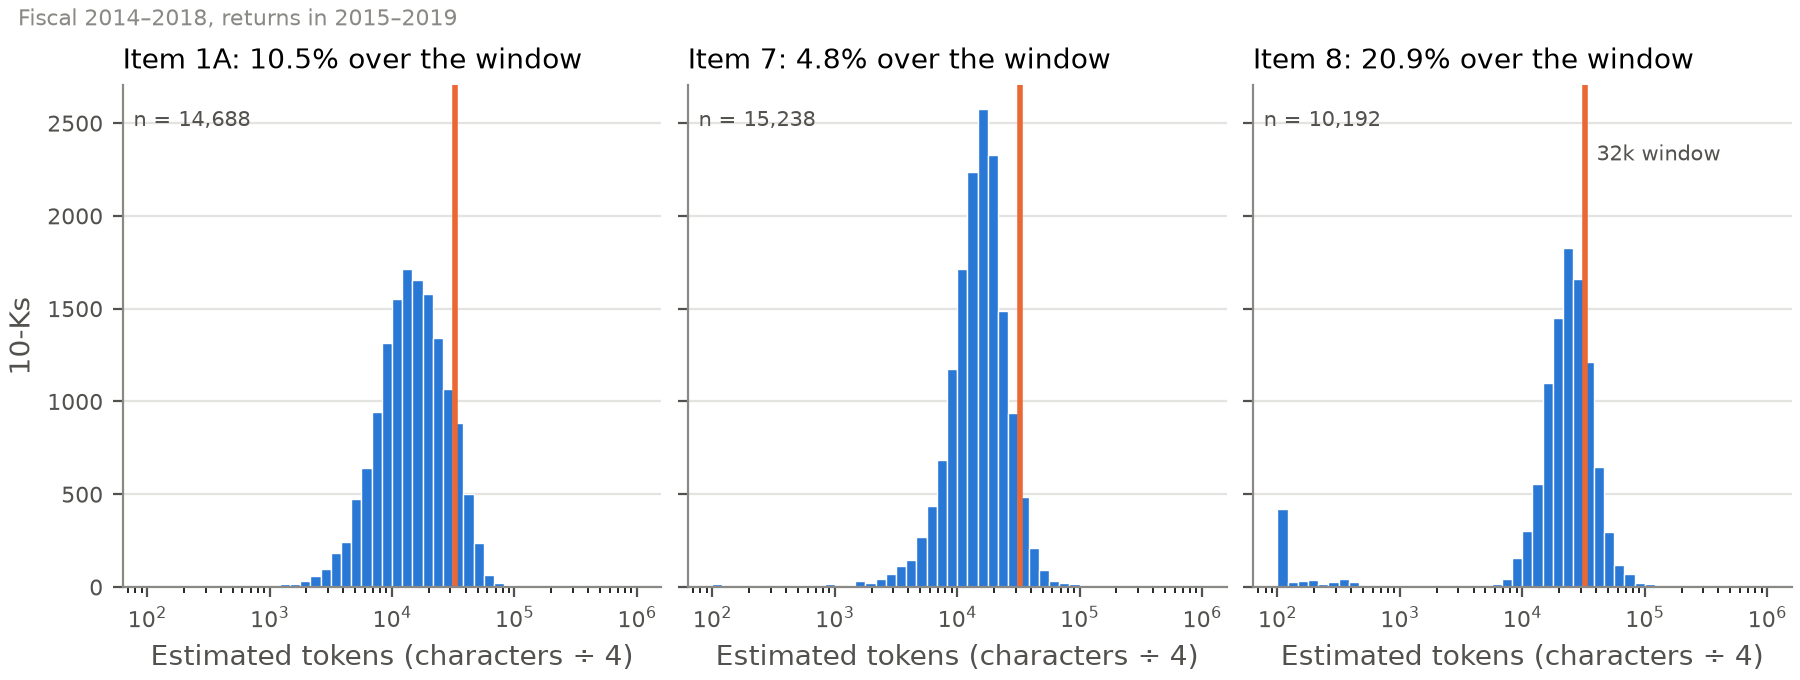

In [8]:
show("section_lengths")

**What this tells us:** we cannot hand the model a whole section; we first have to find
the right passage and send only that.

## 4. Searching for "going concern" is not enough

When an auditor doubts a company can survive the next year, the report says there is
"substantial doubt about its ability to continue as a **going concern**". This is a
strong warning sign. But the words also appear in other places, such as the risk
factors or the management's discussion. In about half of the 10-Ks that contain the
words, they appear outside the sections that hold the financial statements and the
auditor's report (Items 8 and 15), and in about 1 in 8 they appear only outside them.

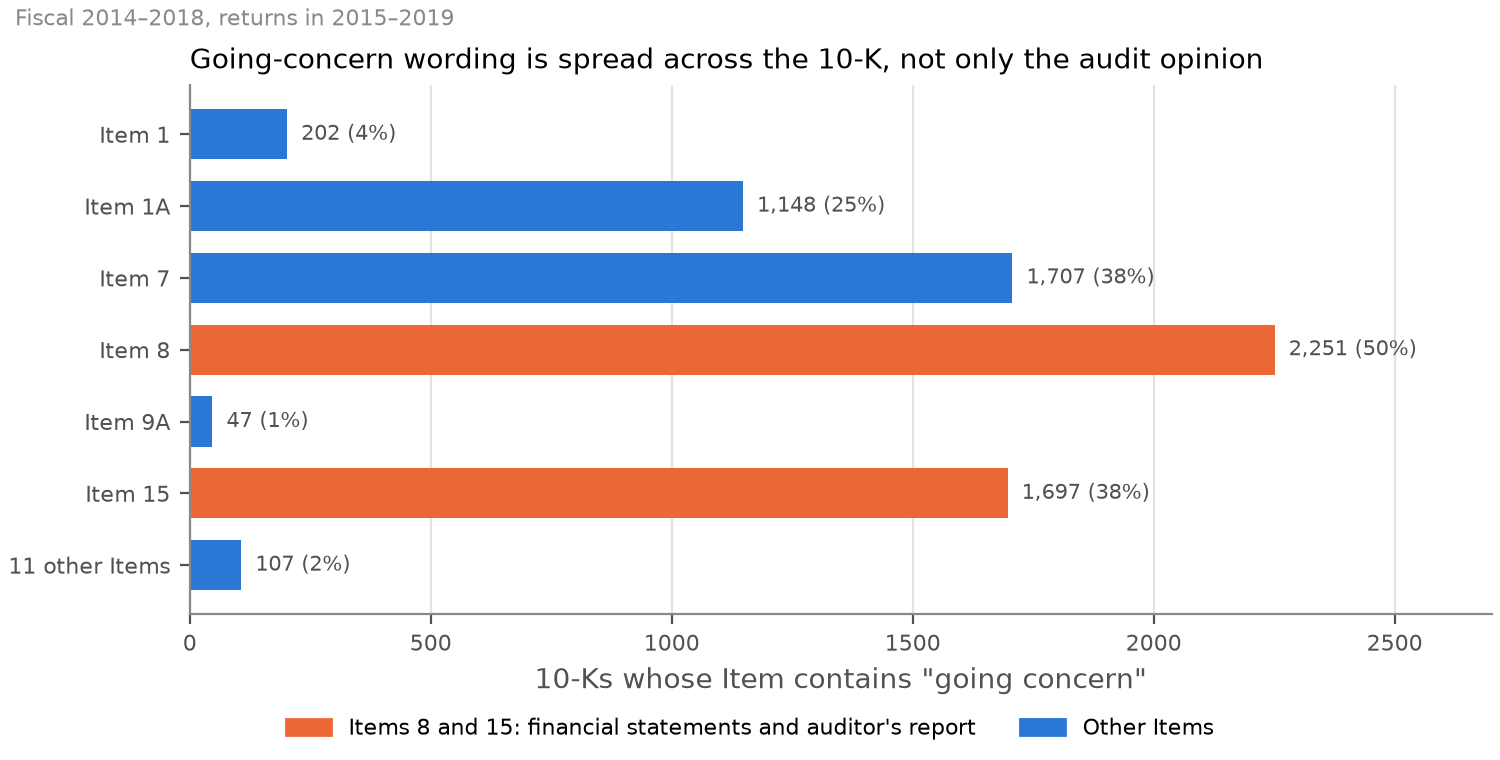

In [9]:
show("going_concern_items")

**What this tells us:** a keyword search finds the words but not their meaning. This is
the job we give the language model.

# More detail

The rest of the exploratory figures, with one line each on what they show.

**Companies per sector.** Financial services is the largest sector, so numbers pooled
over all companies lean towards it.

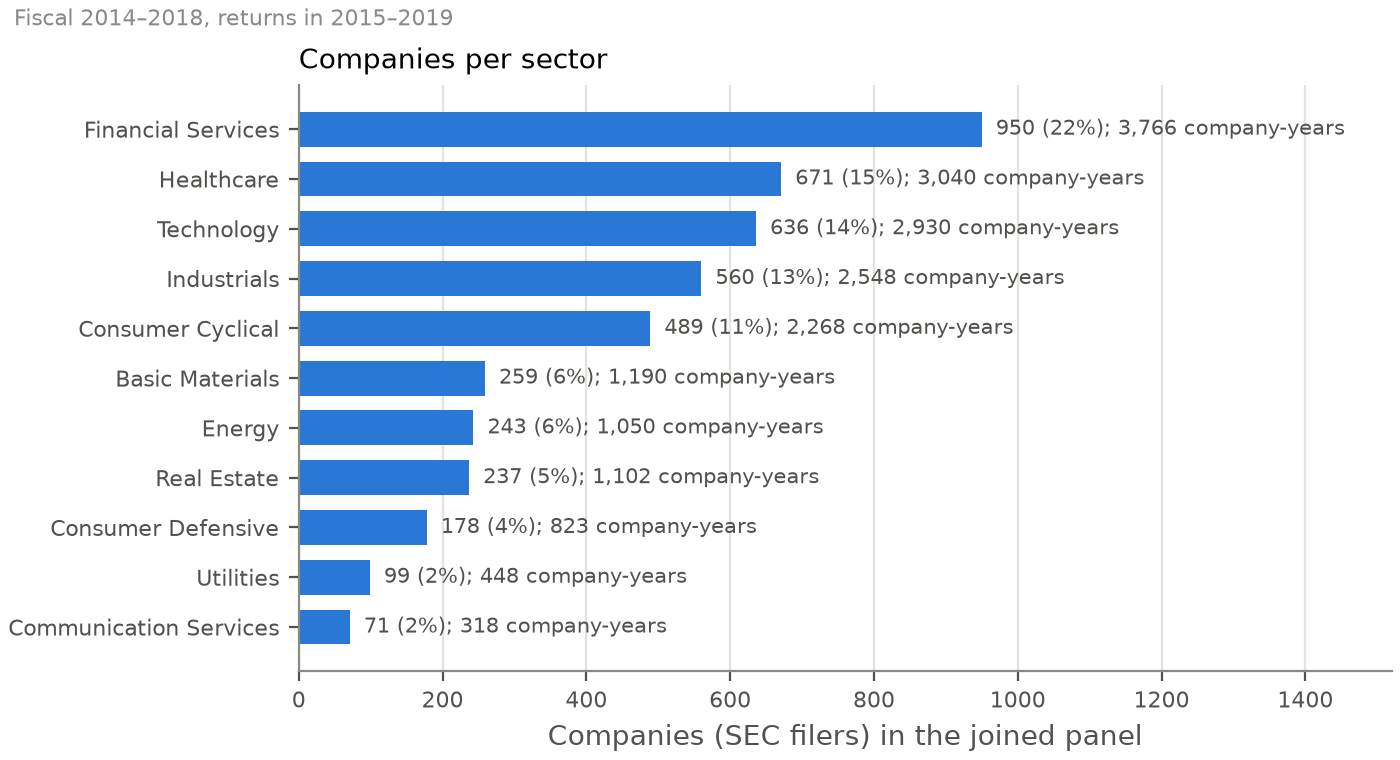

In [10]:
show("companies_per_sector")

**Missing values.** Some numbers are missing for some companies, more often for ratios
than for the basic income statement. We keep these rows; each later step says how it
handles a gap.

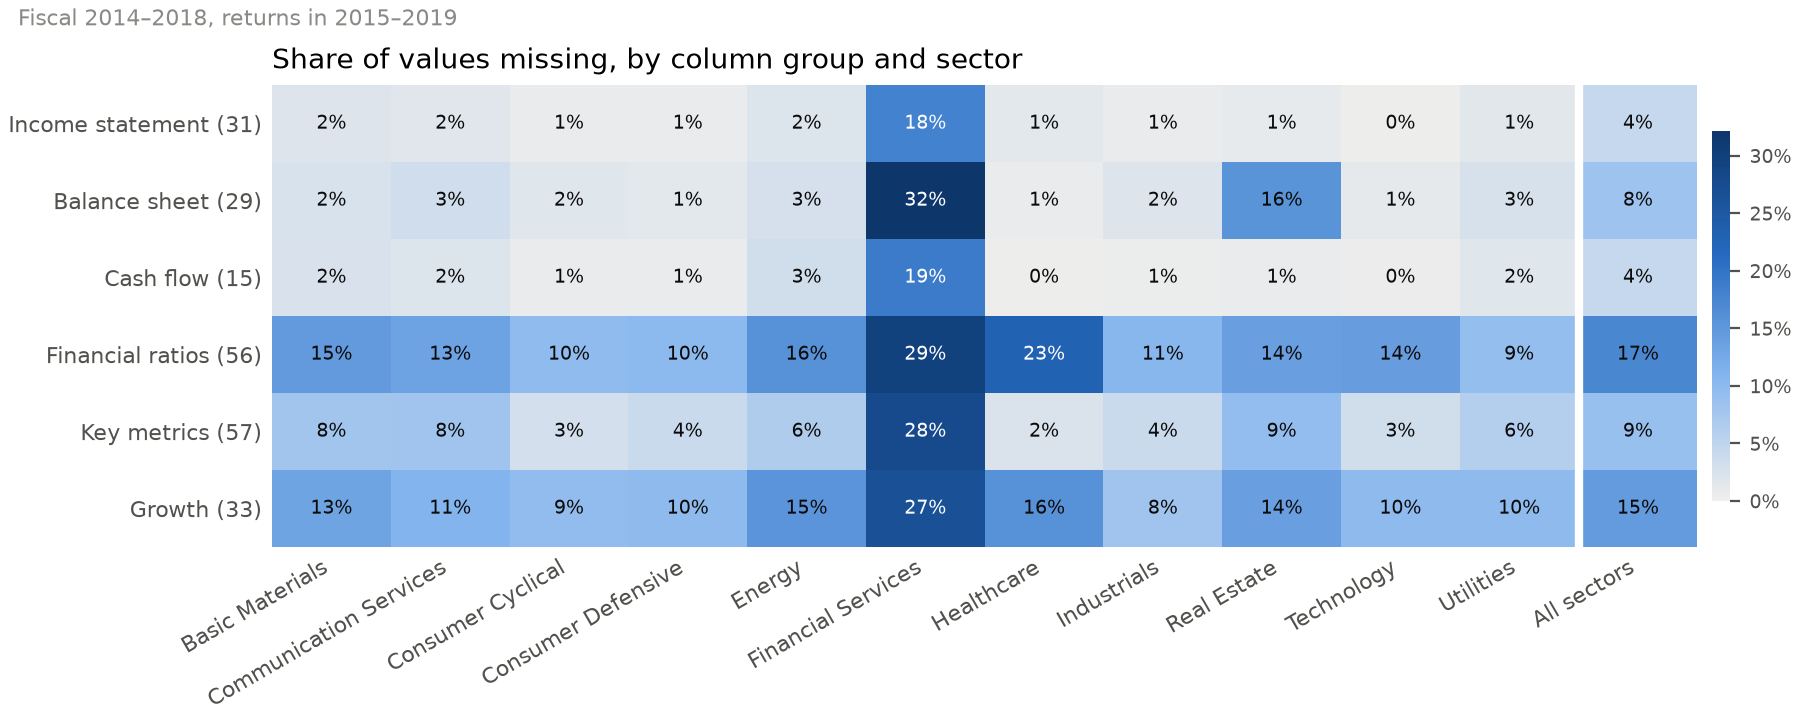

In [11]:
show("missing_values")

**Company size.** Most companies are small: the typical one is worth under a billion
dollars, while the largest 10% hold more than three quarters of all the market value.

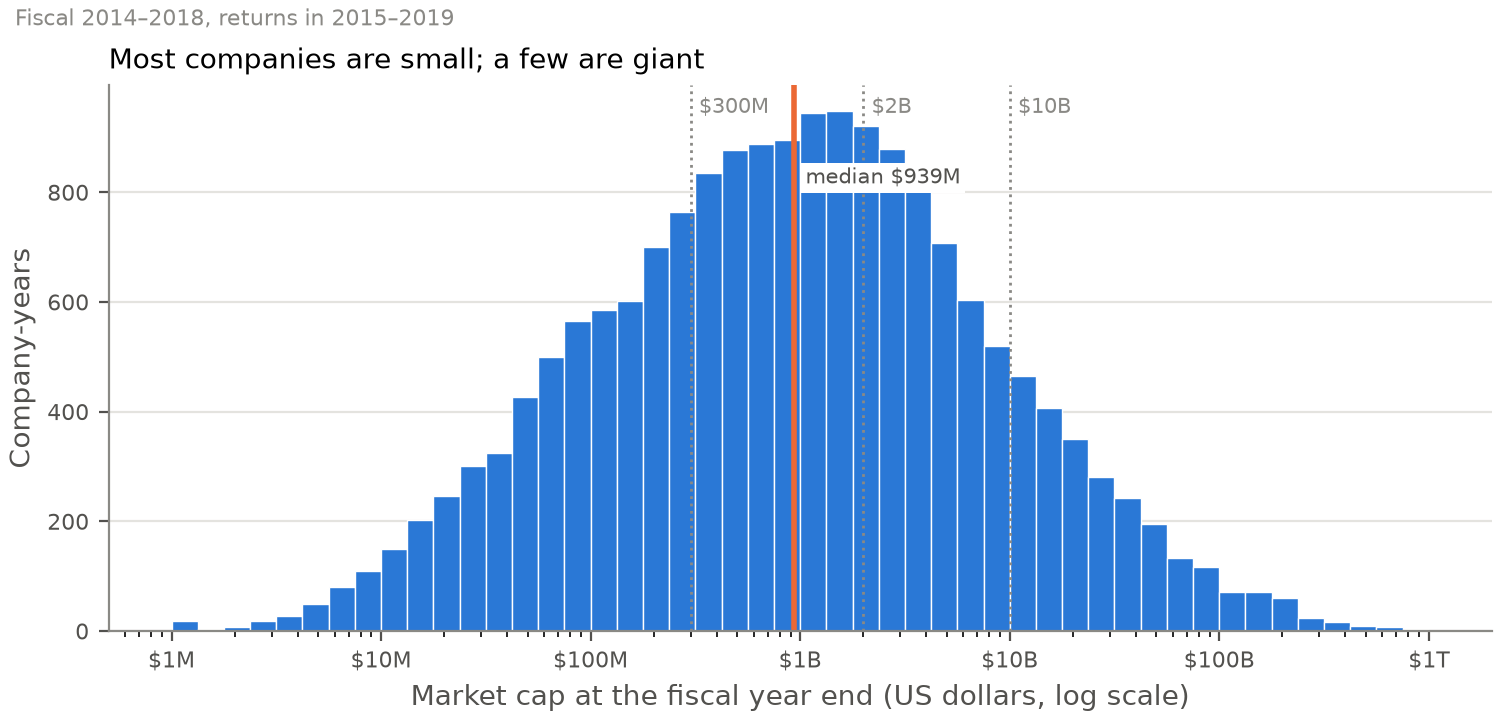

In [12]:
show("market_cap")

**Valuation by sector.** How expensive stocks are compared with their profit
(price-to-earnings) and their book value (price-to-book). About a third of company-years
make a loss, and for them price-to-earnings means nothing.

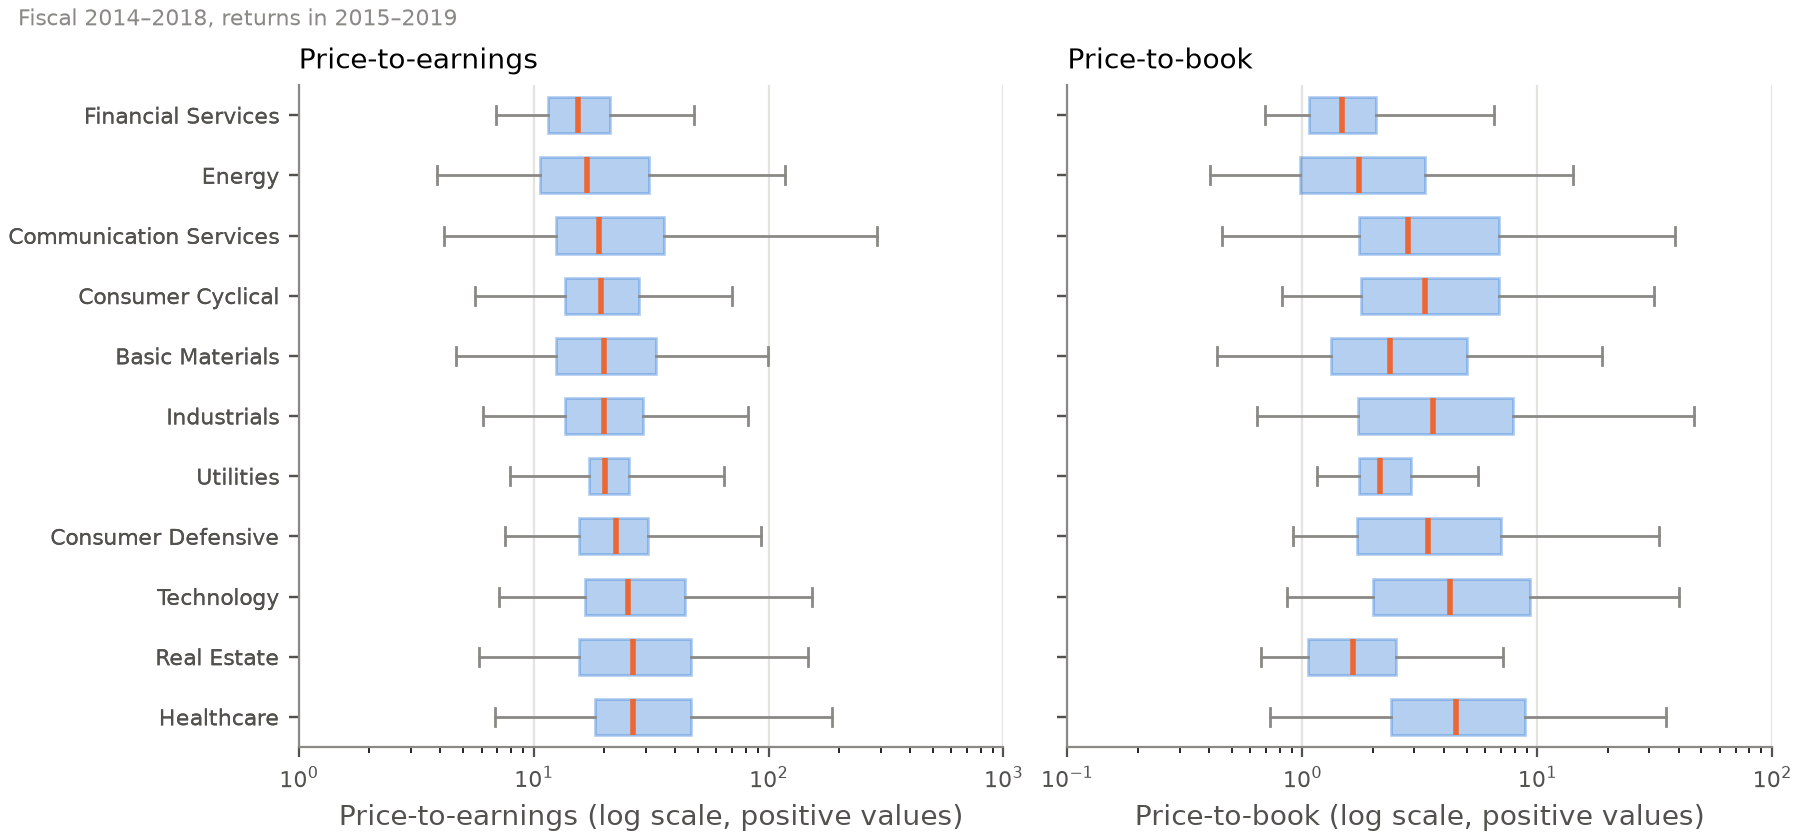

In [13]:
show("valuation_by_sector")

**How the six textbook criteria relate.** Net margin and return on equity move together
strongly, so giving weight to both partly counts the same thing twice.

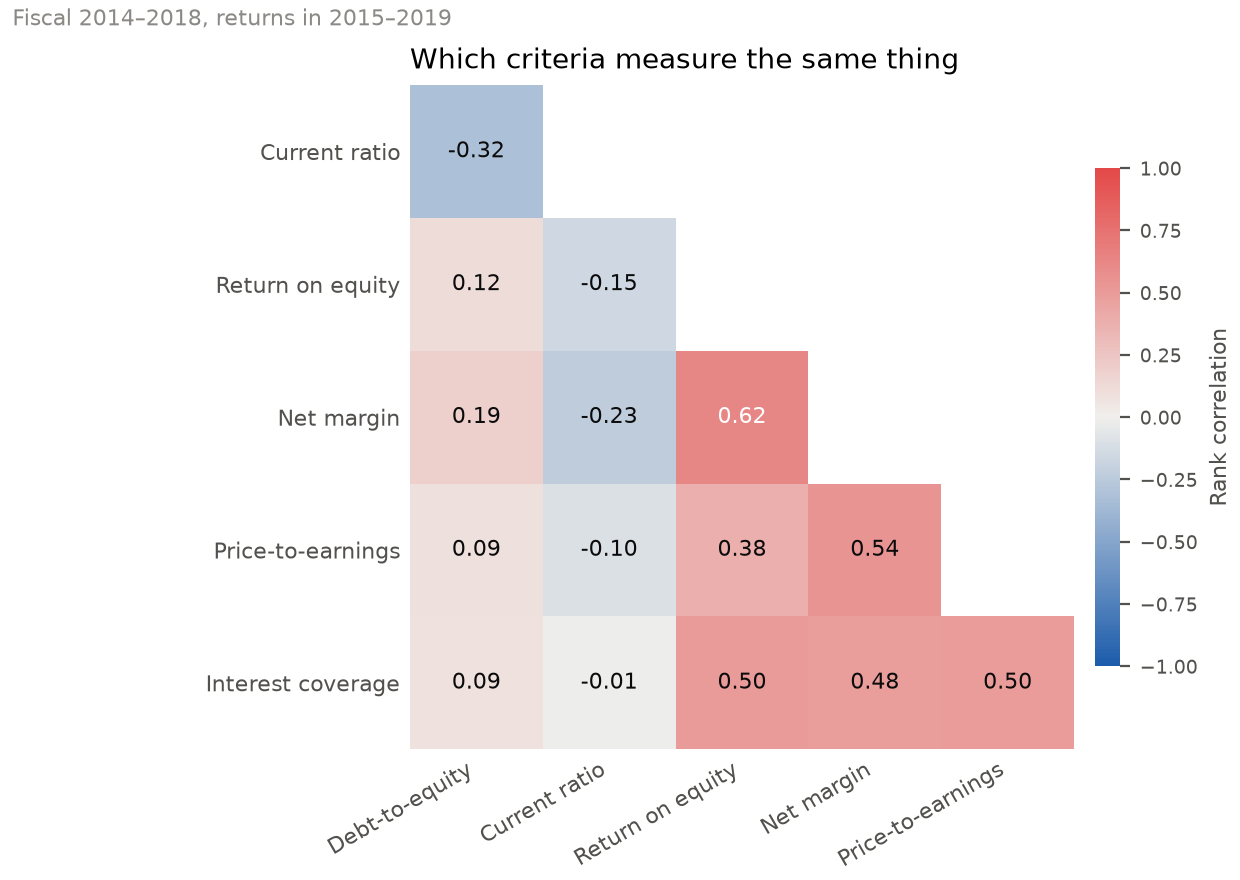

In [14]:
show("criteria_correlation")

**Next-year returns, year by year.** The tail-loser cut-off moves with the market. This
is why it is set within each year: one cut-off for all years would call ordinary
companies in a bad year tail losers.

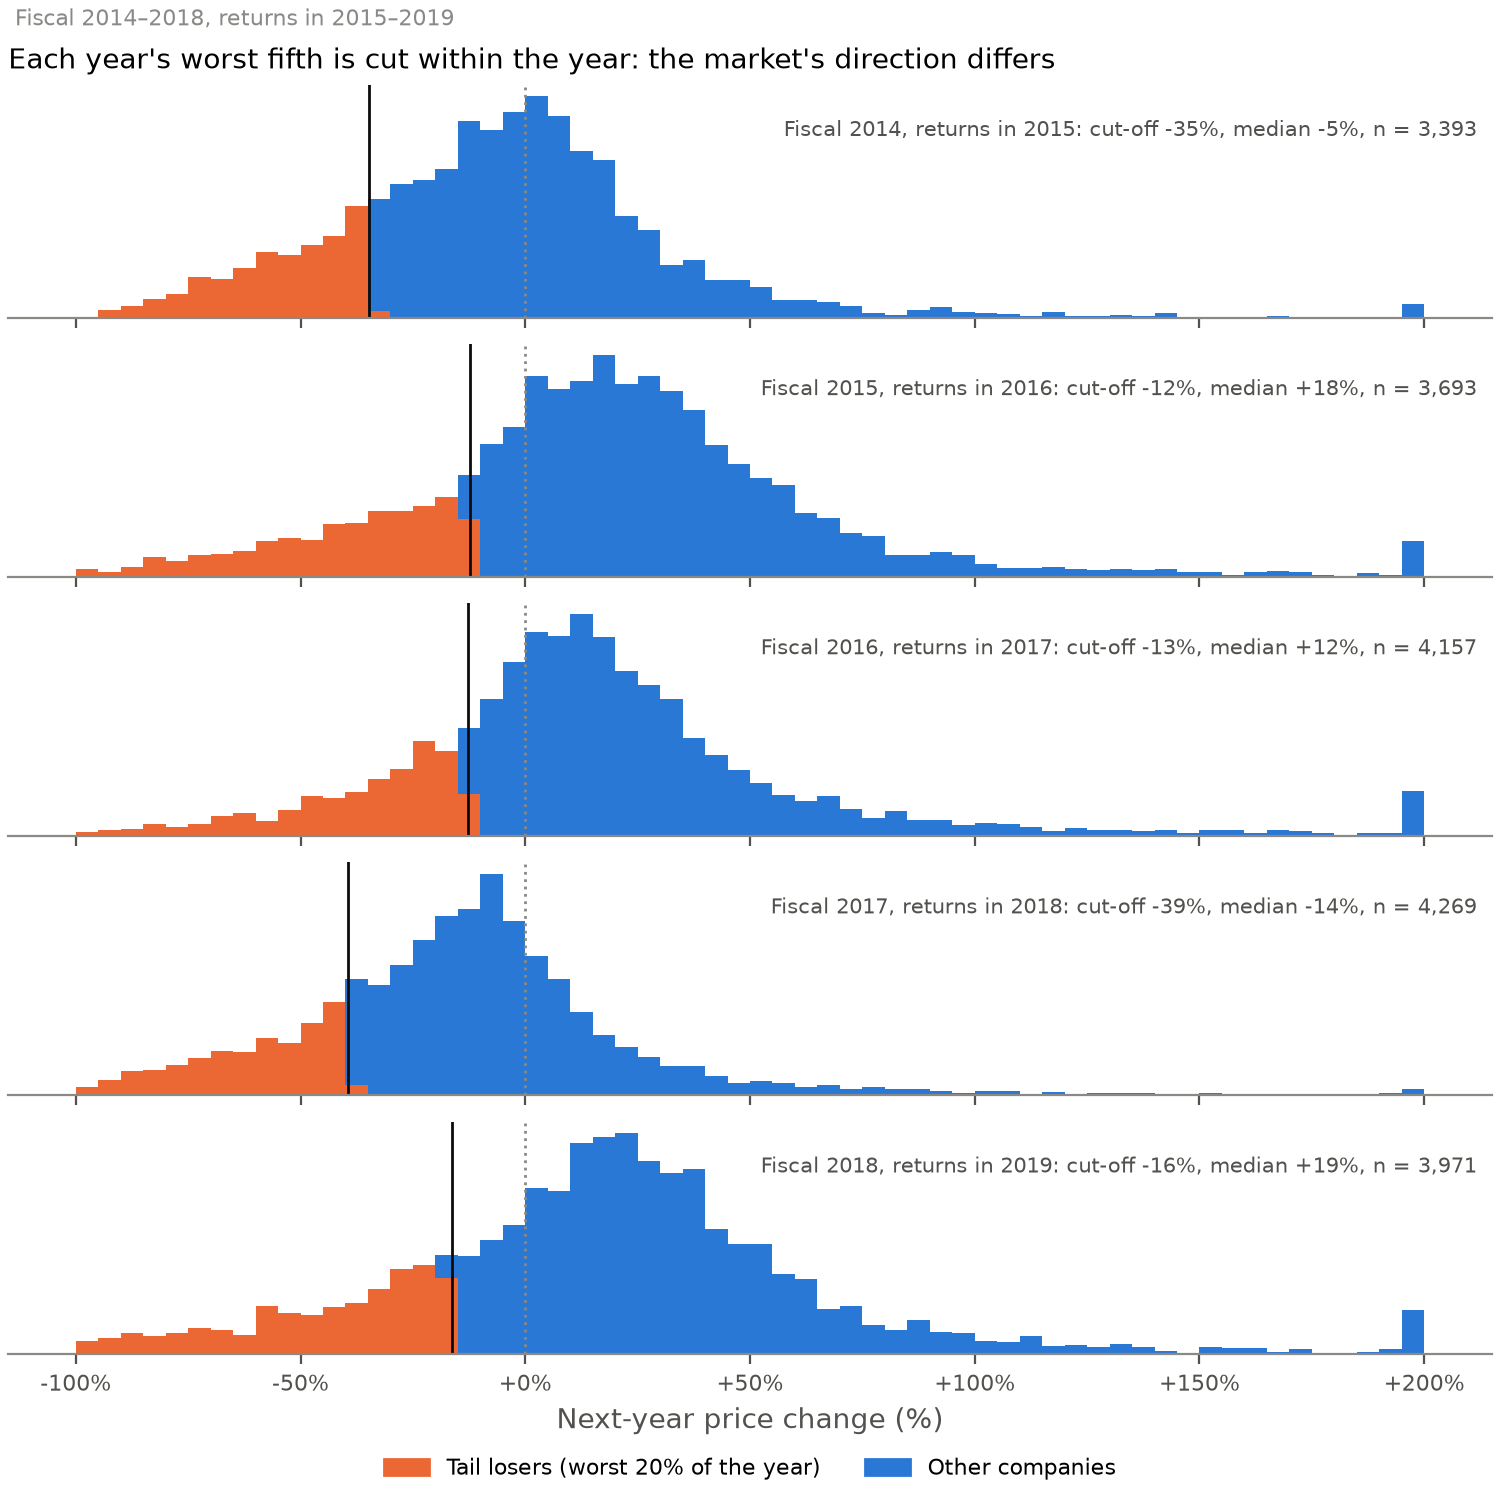

In [15]:
show("return_distribution")

**Tail losers by size and sector.** Small companies are far more often tail losers than
large ones, so any ranking should at least beat "just pick big companies". Healthcare has
the most tail losers, financial services the fewest.

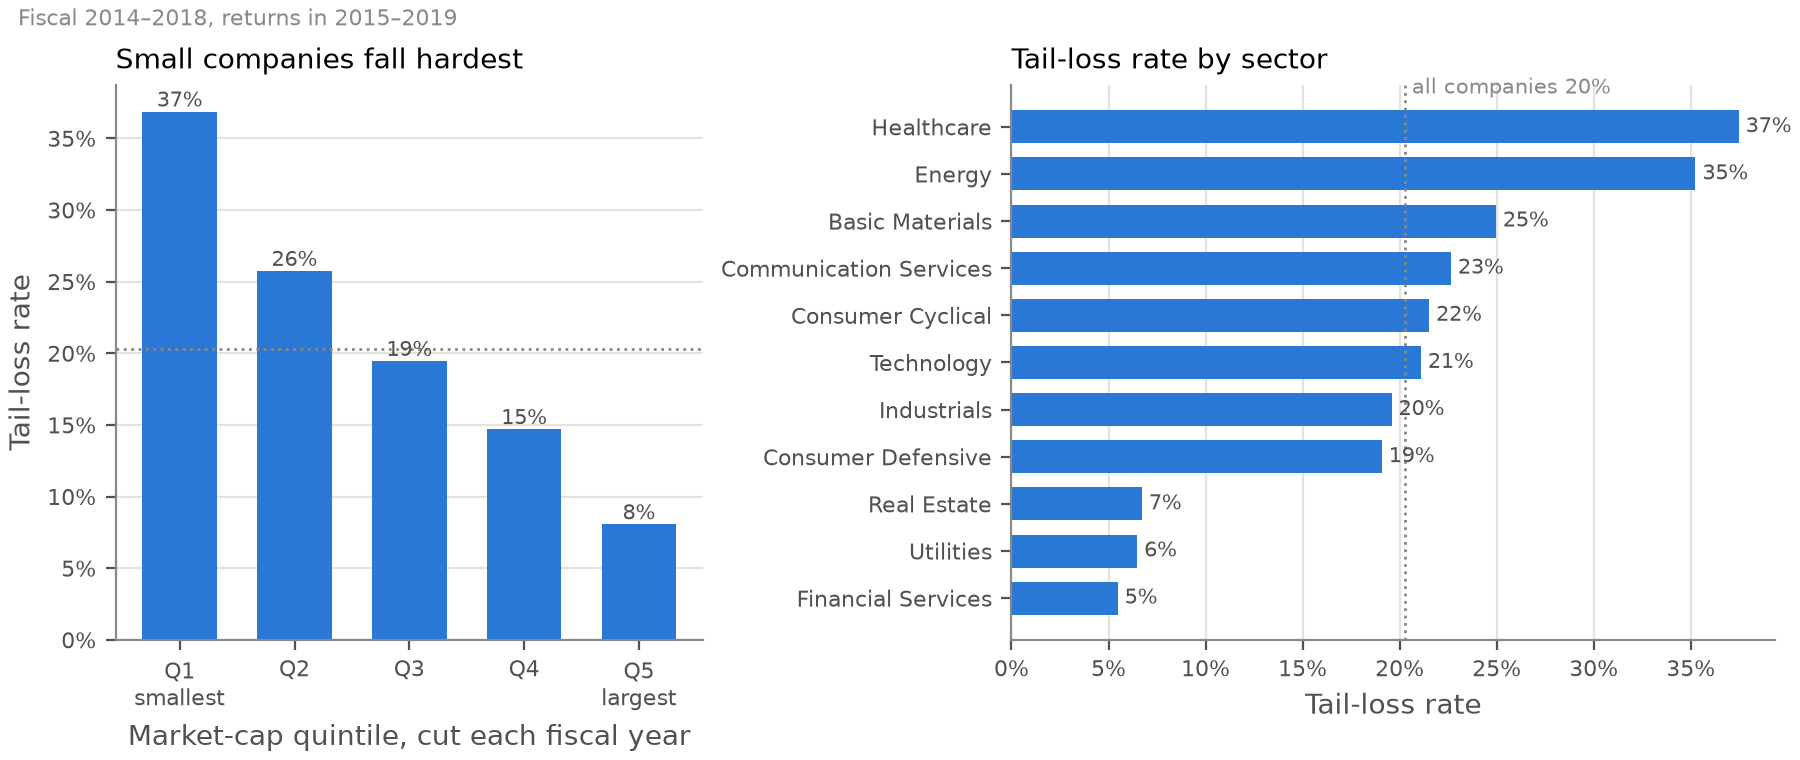

In [16]:
show("tail_loss_by_size_sector")

**Risk-factor sections grow longer every year,** also for the same companies, so the
length problem gets worse over time.

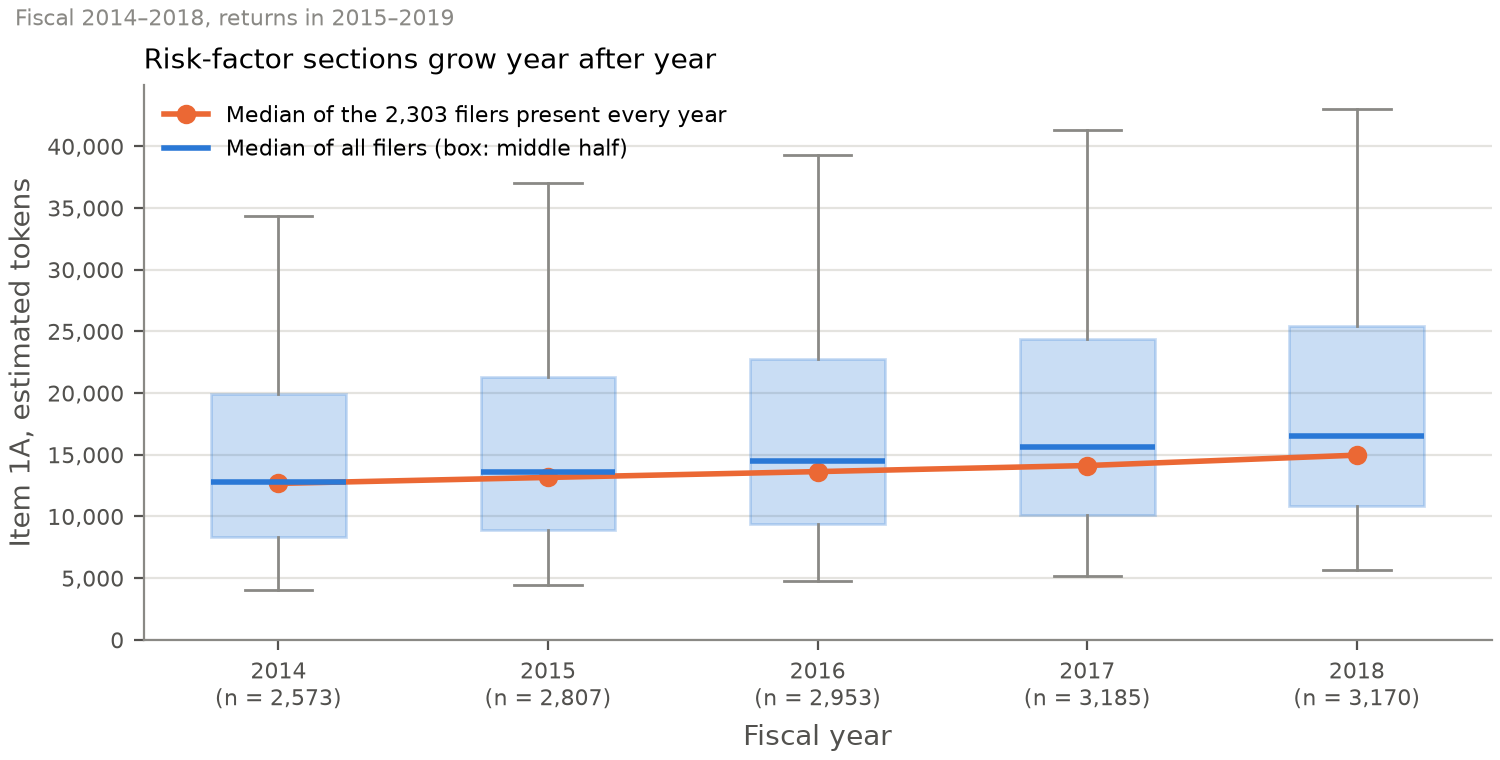

In [17]:
show("item1a_length")

**Filing late.** Tail losers file their 10-K later than other companies and more often
send the SEC a notice that they will be late. This figure uses only 2014 to 2016, to keep
the test years untouched.

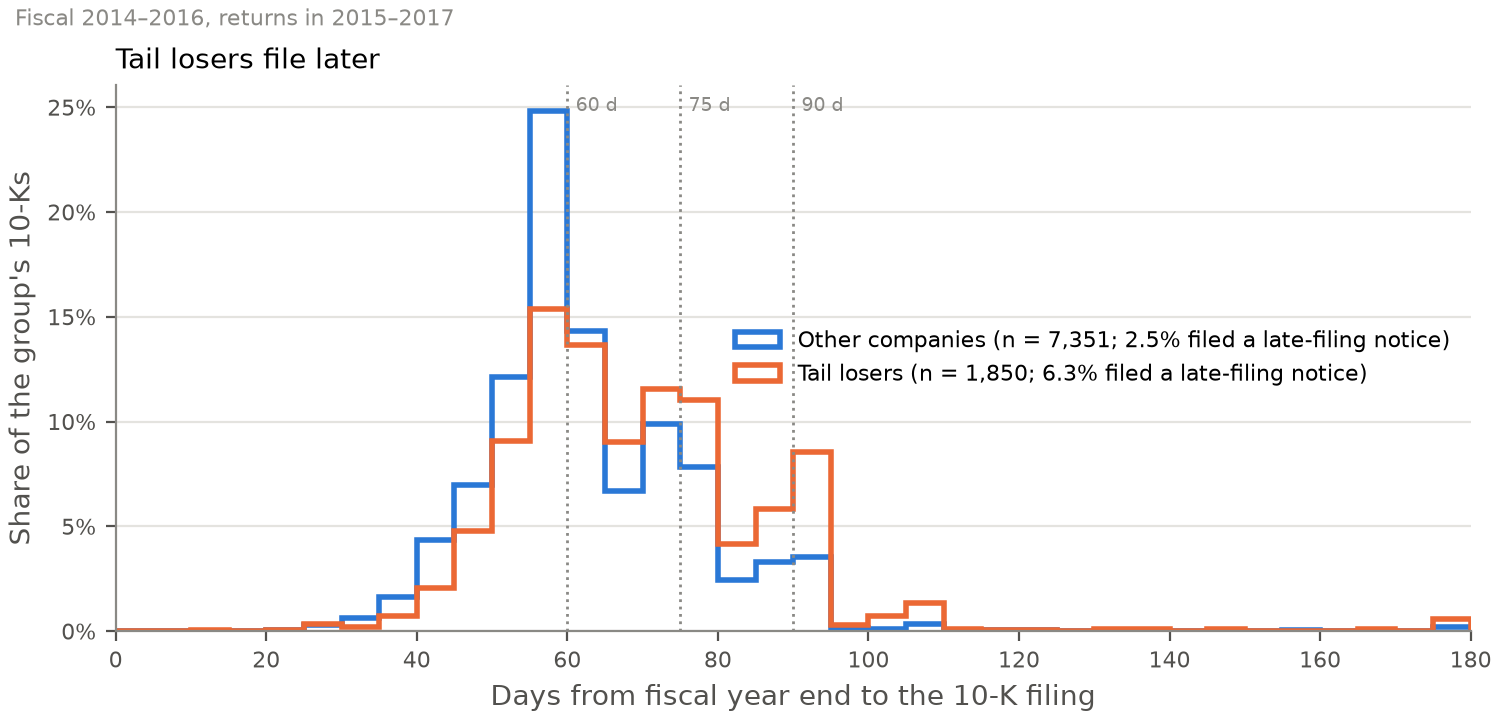

In [18]:
show("filing_lag")

**How much the risk factors change.** Most companies rewrite only a small part of their
risk-factor section from one year to the next.

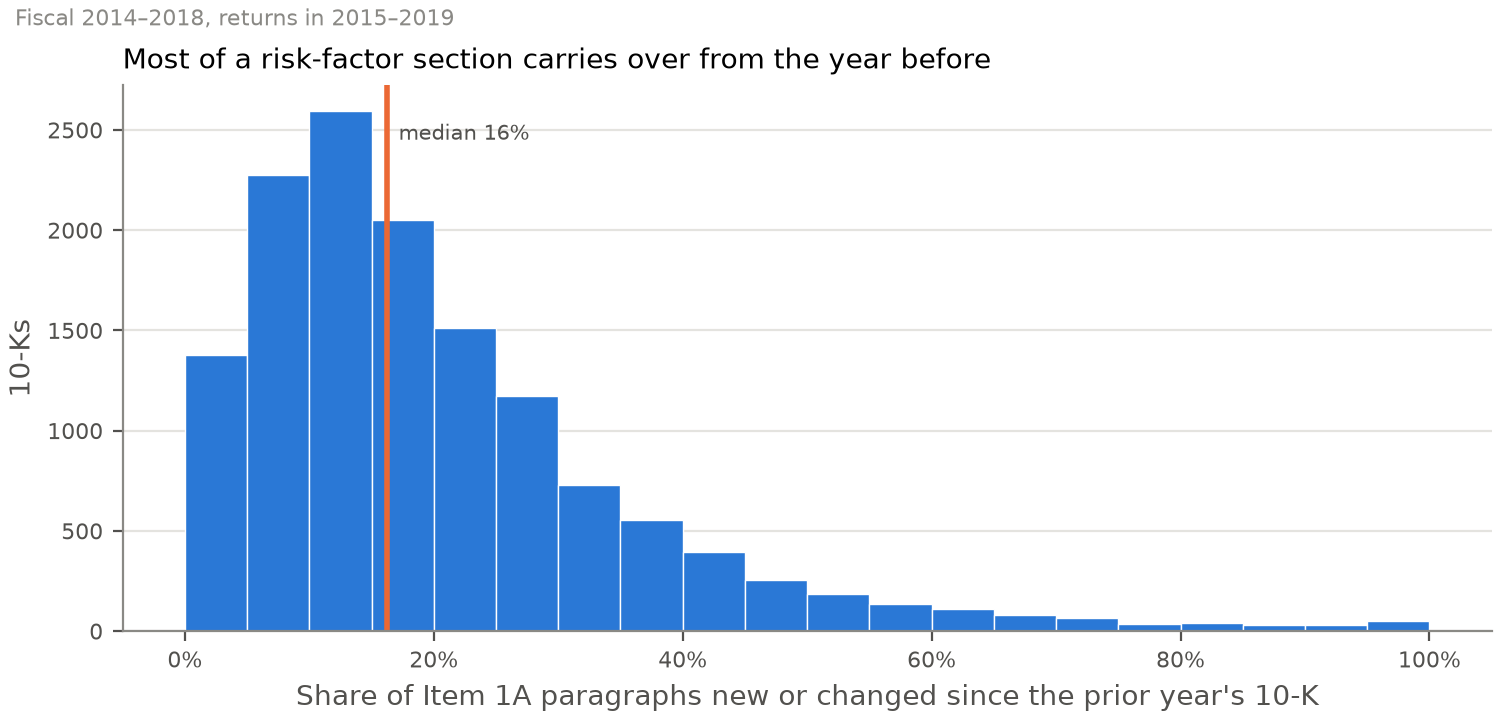

In [19]:
show("item1a_change")

## A worked example

One company seen both ways: Caesars Entertainment in fiscal 2014. On the left, its six
textbook criteria and where it stands among all companies that year. On the right,
passages from its 10-K, including the auditor's going-concern doubt. Its stock then fell
by about half. The numbers place the company; the text says why it may fall.

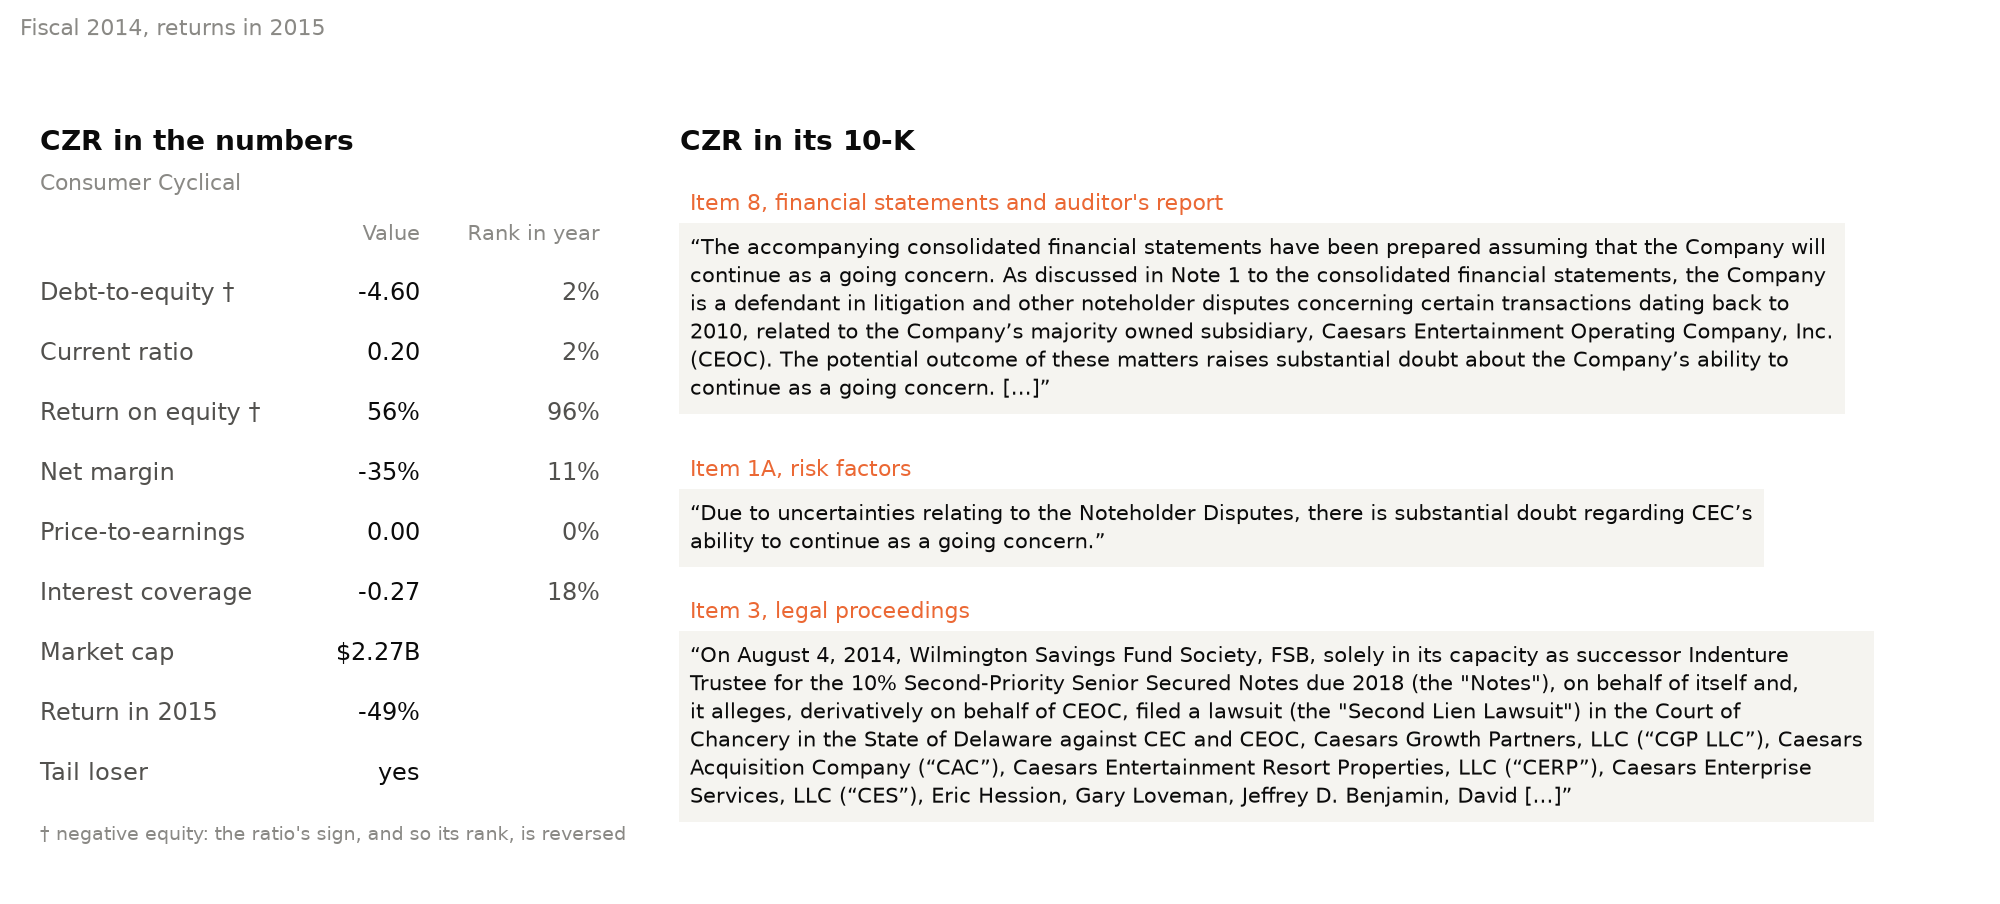

In [20]:
show("worked_example")

# What we take forward

- Companies are linked by their reported figures, not only by ticker, so the tail losers
  stay in the study.
- Ratios are compared within each sector and year, not across the whole market.
- Size is a strong signal on its own, so "rank by size" is a baseline to beat.
- The language model reads short, chosen passages, not whole sections.
- The model's job is to read the meaning of going-concern wording, which a keyword search
  cannot do.